# Урок 15. Цвет с разных сторон

[План курса](../../README_ru.md)

Серый шар остаётся серым при обходе вокруг него. А вот маленькое пятно на лакированной чашке на одном снимке краснее, чем на соседнем. У неподвижной точки сцены могут оказаться разные наблюдаемые цвета. Начнём с пятна, у которого меняется только красный канал.

In [1]:
%matplotlib inline
from pathlib import Path
import sys
course_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'splat_render.py').is_file())
if str(course_root) not in sys.path:
    sys.path.insert(0, str(course_root))
import numpy as np
from IPython.display import display
import matplotlib.pyplot as plt
import splat_render as sr
import splat_demos as demo
lang = "ru"

## Кадр, в котором двигается только цвет

Камера всё время смотрит на центр одного круглого пятна с одинаковым масштабом по трём осям. Расстояние до него тоже постоянно. Слева у пятна фиксированный RGB. Справа в тот же RGB добавляется число, зависящее от направления. У центра непрозрачность равна единице, так что там виден цвет самого пятна. По краям в него подмешивается белый фон.

Если обнулить три направленных коэффициента, правый кадр повторит левый при любом азимуте. По одному ненулевому коэффициенту легко увидеть, какая сторона сферы станет краснее. Наклон камеры открывает направление по вертикали.

In [2]:
display(demo.experiment(15, "ru"))

Зафиксируем, что именно здесь меняется. Рядом с чашкой могло оказаться ещё одно пятно и при повороте закрыть её краешек. Это был бы эффект из прошлого урока. Здесь пятно одно, фон и непрозрачность прежние. Камера обходит пятно по сфере и всё время смотрит ему в центр. Посередине кадра видна одна и та же точка. Если даже при таких условиях значение красного меняется, у рендера появился новый способ описывать цвет.

Горизонтальный поворот удобен для первого опыта. При нулевом возвышении луч лежит в плоскости $xz$. Вертикальный коэффициент может быть хоть единицей, хоть минус единицей, а цвет всё тот же. Причина обнаружится в умножении чуть ниже. Камера выше или ниже этой плоскости даст этому коэффициенту шанс проявиться.

## Направление длины один

Пусть центр камеры $K=(-3,0,0)$, центр пятна $P=(0,0,4)$. Стрелка **от камеры к пятну** равна $P-K=(3,0,4)$. По теореме Пифагора длина $r=\sqrt{3^2+0^2+4^2}=\sqrt{25}=5$. Деление каждой компоненты на пять даёт $d=(0.6,0,0.8)$. Длина теперь единица, ведь $0.6^2+0.8^2=1$. Направление безразмерно, а расстояние больше не меняет цвет. Камера ещё в пяти единицах на той же линии даст ту же стрелку после нормировки.

Все возможные концы таких единичных стрелок лежат на поверхности сферы. Если камера окажется ровно в центре пятна, стрелка будет нулевой и направления не получится. Рендерер пропускает такую точку ещё на проверке глубины. Положительное $y$ здесь направлено вниз в мире исходной камеры. Коэффициенты цвета относятся к мировым осям, поэтому поворот корпуса камеры на месте сам по себе не меняет цвет точки.

In [3]:
direction = np.array([3., 0., 4.])
print(direction / np.linalg.norm(direction))
print(np.round(sr.sh_basis(direction), 6))
np.testing.assert_allclose(sr.sh_basis(direction), sr.sh_basis(2*direction))

[0.6 0.  0.8]
[ 0.282095 -0.        0.390882 -0.293162]


## Четыре карты одной сферы

**Сферическая гармоника** здесь — заранее известное правило, которое по направлению выдаёт число. Весь набор таких правил служит базисом. Для нашей первой карты число одинаково по всей сфере. Ещё три карты плавно меняют знак между противоположными сторонами. Рисунок одной карты задаёт **функция**, а сколько этого рисунка пойдёт в цвет конкретного пятна — **коэффициент**.

В соглашении рендерера Kerbl et al. первые четыре действительные функции идут в порядке:

$$
(Y_0,Y_y,Y_z,Y_x)=(C_0,-C_1d_y,+C_1d_z,-C_1d_x).
$$

Здесь $C_0=1/\sqrt{4\pi}\approx0.282095$ и $C_1=\sqrt{3/(4\pi)}\approx0.488603$. Число $\pi\approx3.14159$ связывает радиус и длину окружности. Выбор этих постоянных уравнивает суммарный квадрат каждой функции по сфере. Например, площадь сферы радиуса один равна $4\pi$. Для постоянной карты $4\pi C_0^2=1$. Для карты $x$ среднее значение $x^2$ по сфере равно $1/3$: оси равноправны, а $x^2+y^2+z^2=1$. Тогда $4\pi C_1^2/3=1$. В самой картинке константа и сила коэффициента всегда работают вместе.

В направлении $(0.6,0,0.8)$ карты дают $(0.282095,0,0.390882,-0.293162)$. Отрицательное значение карты допустимо. Оно означает вычитание соответствующего вклада, а не отрицательную яркость экрана.

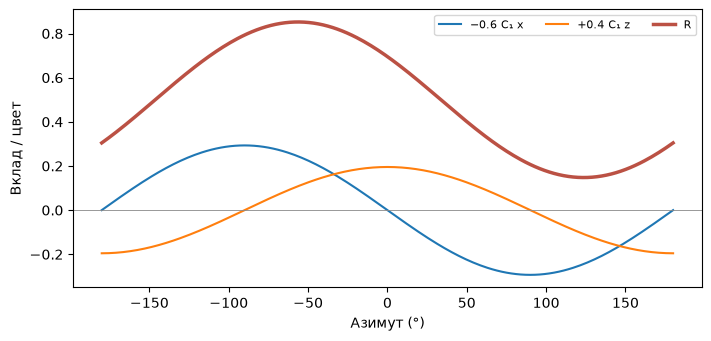

In [4]:
fig = demo.harmonic_curve("ru")
display(fig)
plt.close(fig)

## Из карт — в красный канал

Пусть для красного заданы четыре коэффициента $a=(0,0,0.4,0.6)$. Постоянный сдвиг $0.5$ в кодировке оригинального GS соответствует серому при всех нулевых коэффициентах. Сначала умножаем попарно карту и коэффициент, затем складываем:

$$
\begin{aligned}
R &= 0.5+a_0Y_0+a_yY_y+a_zY_z+a_xY_x \\
  &= 0.5+0+0+0.4\cdot0.390882+0.6\cdot(-0.293162)\\
  &\approx 0.5+0.156353-0.175897=0.480456.
\end{aligned}
$$

У зелёного и синего коэффициенты нулевые, итоговая тройка $(0.480456,0.5,0.5)$. Если требуется постоянный красный $0.8$, достаточно решить $0.8=0.5+a_0 C_0$: вычитаем $0.5$, делим $0.3$ на $0.282095$, получаем $a_0\approx1.0635$. Коэффициент может быть больше единицы. Для показа мы ограничиваем конечный канал промежутком $[0,1]$. В исходном CUDA-вычислении SH на этой стадии отсекаются только отрицательные значения. Выбор места ограничения важен при обучении на очень ярких цветах.

In [5]:
coeff = np.array([[0,0,0], [0,0,0], [.4,0,0], [.6,0,0]])
for d in ([.6,0,.8], [-.6,0,-.8]):
    print(d, np.round(sr.sh_color(d, coeff), 6))
constant = [[(.8-.5)/sr.C0, 0, 0]]
np.testing.assert_allclose(sr.sh_color([0,0,1], constant), [.8,.5,.5])

[0.6, 0, 0.8] [0.480456 0.5      0.5     ]
[-0.6, 0, -0.8] [0.519544 0.5      0.5     ]


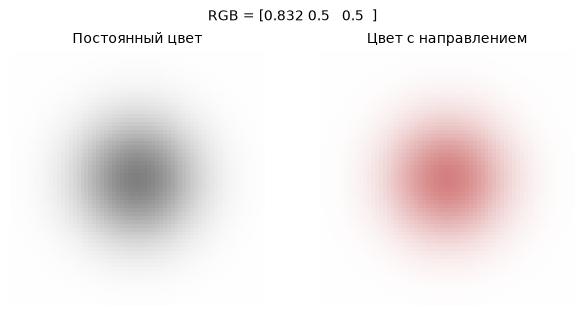

In [6]:
fig = demo.harmonic_figure("ru")
display(fig)
plt.close(fig)

С числом в подписи к рисунку легко запутаться. В ручном расчёте камера давала направление $(+0.6,0,+0.8)$. На рисунке азимут $-36.87^\circ$, поэтому $x$ поменял знак, а $z$ остался прежним. Вклад от карты $x$ теперь прибавляет $0.175897$. Получается $0.5+0.156353+0.175897\approx0.83225$. Это два вида спереди с разных боков. Вид с точно противоположной стороны поменял бы знак ещё и у $z$, как в расчёте над рисунком.

## В обратную сторону. Шесть снимков одного пятна

До сих пор числа для пятна уже были, и по ним строилась картинка. При съёмке чашки всё наоборот. На снимке известен цвет поверхности, известна камера, а в файл сцены надо записать какие-то коэффициенты. Для начала оставим непрозрачное одиночное пятно, наведём камеры ему точно в центр и возьмём только красный канал. В таком опыте можно увидеть, какое наблюдение определило каждое число.

Пусть камеры расположены по обе стороны каждой из трёх осей. В таблице записано направление **от камеры к пятну**, а не положение камеры. Положительному $x$ соответствует камера со стороны отрицательного $x$. У каждой строки ровно одна ненулевая компонента, так что никакие две оси в одном замере не смешиваются.

| Направление луча | Красный в центре |
|---|---:|
| $(+1,0,0)$ | 0.75 |
| $(-1,0,0)$ | 0.35 |
| $(0,+1,0)$ | 0.45 |
| $(0,-1,0)$ | 0.65 |
| $(0,0,+1)$ | 0.70 |
| $(0,0,-1)$ | 0.40 |

Уберём на минуту все множители $C_0,C_1$ из записи. Обозначим буквой $b$ постоянную часть цвета вместе со сдвигом $0.5$. Ещё три числа $g_x,g_y,g_z$ показывают, сколько добавится при единичном шаге по каждой компоненте направления. Тогда красный до ограничения диапазона равен

$$
R(d)=b+g_x d_x+g_y d_y+g_z d_z.
$$

На правом и левом лучах всё, кроме $x$, исчезает. Остаются два коротких равенства, $0.75=b+g_x$ и $0.35=b-g_x$. При сложении справа получится $2b$, слева $1.10$. Половина суммы даёт $b=0.55$. При вычитании, наоборот, исчезнет $b$. Половина разности даёт $g_x=(0.75-0.35)/2=0.20$. Теперь понятно, что записано в таблице. У одной стороны красного на $0.20$ больше среднего, а у другой ровно столько же убавилось. Это среднее по двум **противоположным** направлениям. Для произвольной пары камер такая отмена не работает.

У двух вертикальных снимков среднее опять $0.55$, зато разность сменила знак. Получилось $g_y=(0.45-0.65)/2=-0.10$. Для оставшейся пары $g_z=(0.70-0.40)/2=0.15$. Можно предсказать цвет для камеры, которой в таблице вообще нет. Пусть $d=(0,0.6,0.8)$. Длина уже равна единице. Красный составит $0.55+0-0.10\cdot0.6+0.15\cdot0.8=0.61$. Остальные каналы могли бы иметь совсем другие числа. Сам луч один для всех трёх.

Теперь вернутся карты. В строке формулы перед $d_x$ стояло $-C_1a_x$. Значит, $a_x=-g_x/C_1$. Для $y$ тот же минус, для $z$ плюс. У постоянной карты получается $a_0=(b-0.5)/C_0$. После деления коэффициенты красного в порядке файла $(a_0,a_y,a_z,a_x)$ приблизительно равны $(0.1772,0.2047,0.3070,-0.4093)$. Последний отрицательный, хотя справа в таблице цвет *рос* при положительном $d_x$. Этот знак компенсирует минус в определении самой карты.

In [7]:
rays = np.array([[1, 0, 0], [-1, 0, 0], [0, 1, 0],
                 [0, -1, 0], [0, 0, 1], [0, 0, -1]])
measured = np.array([.75, .35, .45, .65, .70, .40])
basis = np.stack([sr.sh_basis(ray) for ray in rays])
fitted_red, _, rank, _ = np.linalg.lstsq(basis, measured - .5, rcond=None)
held_out = np.array([0., .6, .8])
coeff = np.zeros((4, 3))
coeff[:, 0] = fitted_red
print("a =", np.round(fitted_red, 5))
print("R(0, 0.6, 0.8) =", round(sr.sh_color(held_out, coeff)[0], 5))
assert rank == 4
np.testing.assert_allclose(.5 + basis @ fitted_red, measured)
np.testing.assert_allclose(sr.sh_color(held_out, coeff)[0], .61)

a = [ 0.17725  0.20467  0.307   -0.40933]
R(0, 0.6, 0.8) = 0.61


В таблице `basis` на одну камеру приходится строка из четырёх значений карт. Например, у луча $(+1,0,0)$ эта строка равна $(C_0,0,0,-C_1)$. Умножение строки на столбец коэффициентов даёт сумму четырёх вкладов в один замер. Сдвиг $0.5$ уже учтён в рендере, поэтому из замеров для подгонки он вычитается. `lstsq` выбирает коэффициенты с наименьшей суммой квадратов расхождений по всем строкам. В этом придуманном примере все шесть уравнений совместимы, и расхождение равно нулю с точностью до округления. В фотографии шум хотя бы в одном из парных замеров уже может нарушить равенство трёх средних.

## Четыре камеры, которых не хватило

Теперь оставим только лучи вдоль $+x,-x,+z,-z$. Четыре замера, четыре неизвестных. Кажется, что всё в порядке. Но камера двигалась только в горизонтальной плоскости, и в каждой из четырёх строк множитель при $a_y$ равен нулю. Добавление ещё ста камер на той же окружности не откроет ни одной ненулевой строки в этом столбце. Два совершенно разных значения $g_y$, например $-0.10$ и $+0.20$, одинаково точно объяснят все эти фотографии. У задачи сохранилось всего три независимых сочетания чисел. Именно это означает `rank = 3` в расчёте.

Решатель ниже для неопределённого коэффициента выберет ноль. Среди подходящих решений у него самая маленькая длина вектора коэффициентов. Ноль здесь рассказывает о выборе решателя. Подтвердить его фотографией пока нечем. На новом направлении $(0,0.6,0.8)$ получится $0.55+0+0.12=0.67$, хотя реальный замер из нашего опыта был $0.61$. Если задать $g_y=+0.20$, выйдет уже $0.55+0.12+0.12=0.79$. На графике все три линии проходят через одну точку при $d_y=0$, но расходятся по мере ухода камеры с горизонтальной орбиты.

Достаточно добавить одну камеру с лучом $(0,+1,0)$. На ней наблюдалось $0.45$, а постоянная часть уже известна, $0.55$. Разность $0.45-0.55=-0.10$ возвращает недостающее $g_y$. При этом камеру с направлением $(0,0.6,0.8)$ по-прежнему можно держать в стороне. Она не подсказала ни одного коэффициента, поэтому совпадение с её цветом уже проверяет предсказание.

rank = 3
R = [0.67 0.79 0.61]


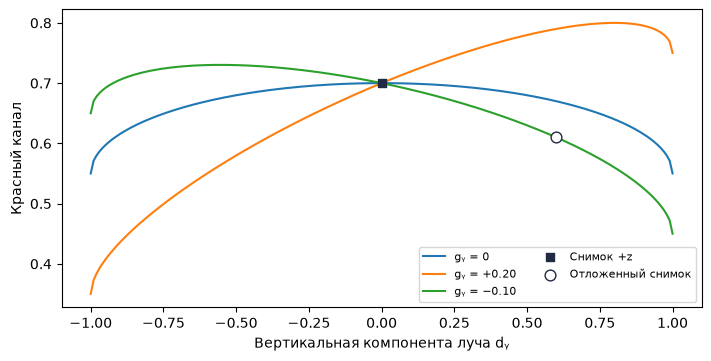

In [8]:
flat = [0, 1, 4, 5]
plane_red, _, plane_rank, _ = np.linalg.lstsq(basis[flat], measured[flat] - .5, rcond=None)
one_more = flat + [2]
recovered = np.linalg.lstsq(basis[one_more], measured[one_more] - .5, rcond=None)[0]
also_fits = plane_red.copy()
also_fits[1] = -.20 / sr.C1
for estimate in (plane_red, also_fits, recovered):
    np.testing.assert_allclose(.5 + basis[flat] @ estimate, measured[flat])
print("rank =", plane_rank)
predictions = [.5 + sr.sh_basis(held_out) @ a for a in (plane_red, also_fits, recovered)]
print("R =", np.round(predictions, 3))
np.testing.assert_allclose(predictions, [.67, .79, .61])
assert plane_rank == 3

vertical = np.linspace(-1., 1., 201)
section = np.array([sr.sh_basis([0, y, np.sqrt(1 - y*y)]) for y in vertical])
ru = lang == "ru"
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
for label, a in [("gᵧ = 0", plane_red), ("gᵧ = +0.20", also_fits), ("gᵧ = −0.10", recovered)]:
    ax.plot(vertical, .5 + section @ a, label=label)
ax.scatter([0], [.70], marker="s", color="#202a42", zorder=4,
           label="Снимок +z" if ru else "+z photograph")
ax.scatter([.6], [.61], marker="o", s=60, facecolors="white", edgecolors="#202a42", zorder=4,
           label="Отложенный снимок" if ru else "Held-out photograph")
ax.set(xlabel="Вертикальная компонента луча dᵧ" if ru else "Vertical ray component dᵧ",
       ylabel="Красный канал" if ru else "Red channel")
ax.legend(fontsize=8, ncol=2)
display(fig)
plt.close(fig)

На графике расстояние до камеры всюду одно и то же. Для каждой точки кривой $d_x=0$, а $d_z=\sqrt{1-d_y^2}$, так что луч остаётся единичным и смотрит с передней половины сферы. Закрашенный квадрат обозначает один из четырёх горизонтальных снимков. Белый кружок отмечает отдельный проверочный снимок. Он остаётся проверочным даже после добавления вертикальной камеры. У кривых разные наклоны, поэтому кружок отделяет удачное предсказание от тех, которые всего лишь хорошо объясняли горизонт.

## Что именно прочитано с фотографии

С непрозрачным центром мы могли подставить число прямо из пикселя. На краю пятна это дало бы другие коэффициенты у того же самого материала. Пусть красный у чашки $c=0.70$, у фона $B=1$, а до пикселя дошла половина веса пятна, $\alpha=0.5$. По прошлому уроку пиксель содержит $I=\alpha c+(1-\alpha)B=0.5\cdot0.70+0.5\cdot1=0.85$. Записав $0.85$ как цвет чашки, мы записали заодно и половину белого фона.

Когда известны и фон, и вес, этот шаг можно обратить. Из $I$ вычитается известная доля фона $(1-\alpha)B$, остаток делится на $\alpha$. В нашем пикселе $(0.85-0.5)/0.5=0.70$. На самом краю при $\alpha=0.05$ тот же расчёт уже усиливает погрешность в двадцать раз. Ошибка измерения на $0.01$ превращается в ошибку цвета на $0.01/0.05=0.20$. При нулевом весе пиксель целиком принадлежит фону, и делить уже не на что. Два наложенных пятна ещё сложнее. Из одного RGB приходится разбирать вклады сразу двух неизвестных цветов и их весов. Поэтому в общей сцене сравниваются целые отрендеренные изображения с фотографиями, а в подгонке участвуют и геометрия, и видимость.

Есть ещё одна потеря информации. Два коэффициента при луче $+z$, $a_z=1.6$ и $a_z=2$, с нулевыми остальными дадут красные примерно $1.282$ и $1.477$. В учебном рендере оба прижмутся к единице. Белый по этому каналу пиксель говорит, что граница достигнута. Из него нельзя восстановить величину превышения. Подгонка по неограниченной формуле выше работала именно потому, что все шесть замеров лежали внутри диапазона, вдали от его концов.

## Сколько значений хранит пятно

Постоянная карта имеет степень 0. Степень 1 добавляет три карты. Суммарно до степени $l$ включительно их $(l+1)^2$. Для $l=1$ получаем $(1+1)^2=4$ коэффициента на канал, всего $4\cdot3=12$ чисел на RGB. При $l=3$ их $16\cdot3=48$. Старшие степени позволяют быстрее менять цвет с направлением. Очень узкий блик по-прежнему трудно уложить в несколько плавных карт. Коэффициенты обучаются по фотографиям; они описывают наблюдаемую зависимость и сами по себе не задают положение лампы. [Определение направления и знаков в исходном рендерере](https://github.com/graphdeco-inria/diff-gaussian-rasterization/blob/main/cuda_rasterizer/forward.cu).

## Насколько узким может быть блик

На полированной чашке бывает небольшой яркий блик. Камера едва сдвинулась, и на его месте уже виден основной цвет. На горизонтальном круге пусть красный в самом блике равен $0.8$, а под углами $90^\circ$, $-90^\circ$ и $180^\circ$ он опустился до $0.3$. Уместятся ли хотя бы эти четыре числа в степень 1?

У любой пары противоположных лучей сумма равна $2b$, поскольку направленные добавки противоположны. Для $0^\circ$ и $180^\circ$ сумма получилась $0.8+0.3=1.1$. Для второй противоположной пары $0.3+0.3=0.6$. Одно и то же $2b$ одновременно двум числам равняться не может. Несовпадение видно и без подбора коэффициентов. Например, кривая, которая попала в максимум и в точку за чашкой, имеет среднее $0.55$ и амплитуду по $z$ величиной $0.25$. В обе боковые точки она положит $0.55$, если оставить симметрию по $x$. Добавка по $x$ сможет уменьшить одно из этих значений только за счёт увеличения второго.

На рисунке узкий блик задан простой функцией. Для угла $\theta$ берётся положительная часть $\cos\theta$, возводится в двадцатую степень и умножается на $0.5$. Небольшие значения после такого возведения быстро сходят на нет, а единица остаётся единицей. После прибавления $0.3$ получается тёмная поверхность со светлой полоской углов. Старшие гармоники дают больше раздельных изгибов вокруг сферы, за каждый из них придётся платить коэффициентами и покрытием подходящих ракурсов. Смена положения лампы — уже другой опыт. Коэффициенты подогнаны по прежнему освещению и без новой информации не подскажут, куда на чашке переедет блик.

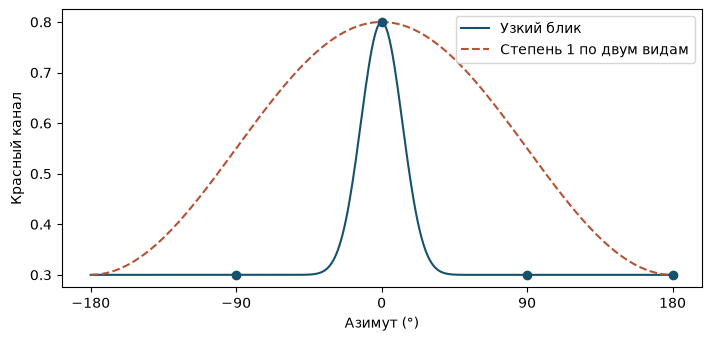

In [9]:
degrees = np.linspace(-180, 180, 361)
cosine = np.cos(np.deg2rad(degrees))
target = .30 + .50 * np.maximum(cosine, 0) ** 20
first_degree = .55 + .25 * cosine
fig, ax = plt.subplots(figsize=(7, 3.3), layout="constrained")
ax.plot(degrees, target, color="#16516e",
        label="Узкий блик" if ru else "Narrow highlight")
ax.plot(degrees, first_degree, "--", color="#b45336",
        label="Степень 1 по двум видам" if ru else "Degree 1 through two views")
ax.scatter([-90, 0, 90, 180], [.30, .80, .30, .30], color="#16516e", zorder=3)
ax.set(xlabel="Азимут (°)" if ru else "Azimuth (°)",
       ylabel="Красный канал" if ru else "Red channel", xticks=[-180,-90,0,90,180])
ax.legend()
display(fig)
plt.close(fig)

## Опыты и разбор

Что получится с противоположной стороны сферы? А если поменять принятую стрелку на «от пятна к камере», сохранив тот же внешний вид?

<details><summary>Разбор</summary>

У противоположного направления три линейные карты меняют знак. Наш красный равен $0.5-0.156353+0.175897=0.519544$. Нулевая степень одинакова с обеих сторон. Чтобы перенести модель между двумя противоположными соглашениями, одновременно меняются знаки трёх коэффициентов степени 1; два минуса в каждом произведении сокращаются.

</details>

**Другой постоянный цвет.** У пятна должен быть один и тот же RGB $(0.2,0.5,0.8)$ со всех сторон. Какие три числа останутся в файле при степени 0?

<details><summary>Разбор</summary>

Постоянная карта для каждого канала даёт $0.5+C_0a_0$. После вычитания $0.5$ из нужного RGB остаётся $(-0.3,0,+0.3)$. Деление каждого числа на $0.282095$ даёт тройку приблизительно $(-1.0635,0,+1.0635)$. Отрицательный коэффициент красного вполне пригоден. При умножении на карту он лишь убирает $0.3$ от серого. Камеру можно переносить вокруг пятна, а эта операция будет давать тот же результат.

</details>

**Почти горизонтальный луч.** Все параметры известны, кроме $g_y$. После вычитания известных вкладов от постоянной части, $x$ и $z$ у камеры с $d_y=0.02$ остался красный $0.004$. Насколько устойчиво это измерение, если сам пиксель мог ошибиться на $0.01$?

<details><summary>Разбор</summary>

После вычитания остался член $g_y d_y$. Деление даёт $g_y=0.004/0.02=0.20$. Та же операция делит возможную ошибку на $0.02$, поэтому погрешность коэффициента достигает $0.01/0.02=0.50$, больше самого найденного значения. Направление с $d_y=1$ при той же точности и тех же известных остальных параметрах снизит погрешность коэффициента до $0.01$. Высота отличалась от нуля в обоих случаях, но почти плоская орбита даёт слишком слабый сигнал.

</details>

**Край чашки стал светлее.** В двух снимках край имеет красный $0.76$ и $0.88$ на белом фоне. Известные локальные непрозрачности равны $0.8$ и $0.4$. Сколько красного у самого пятна в каждом случае и нужен ли направленный коэффициент для объяснения этой пары?

<details><summary>Разбор</summary>

В первом пикселе фон дал $1-0.8=0.2$. Цвет пятна равен $(0.76-0.2)/0.8=0.70$. Во втором фон дал $0.6$, поэтому $(0.88-0.6)/0.4=0.70$. Оба наблюдения объясняются одним цветом. Если отбросить веса и сразу обучать гармоники по $0.76$ и $0.88$, в файл попадёт ложная зависимость от ракурса. Этот пример соединяет цвет с прошлым уроком и объясняет, зачем следующему блоку понадобятся кадры с разных камер.

</details>